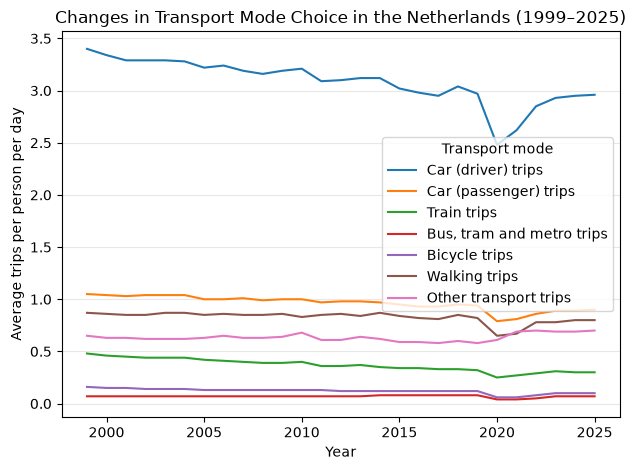

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the dataset
df = pd.read_csv(
    "Data_age_research/mobilieitstrend per rit, vervoerwijzen, reismotief, leeftijd en geslacht.csv",
    sep=";",
    skiprows=5,
    header=[0, 1, 2, 3],
    decimal=",",
    na_values=[".", ""]
)

# Select all transport modes for the total population
# and all travel purposes
columns = [
    col for col in df.columns
    if col[0] not in ["Perioden", "Totaal"]
    and col[1] == "Totaal"
    and col[2] == "Totaal"
]

# Extract the years
years = pd.to_numeric(
    df.iloc[:, 0].astype(str).str.replace("*", "", regex=False),
    errors="coerce"
)

# Keep the years 1999–2025
mask = years.between(1999, 2025)

labels = [
    "Car (driver) trips",
    "Car (passenger) trips",
    "Train trips",
    "Bus, tram and metro trips",
    "Bicycle trips",
    "Walking trips",
    "Other transport trips"
]

for i, col in enumerate(columns[:-1]): #exclude the last column which is "Totaal"
    plt.plot(
        years[mask],
        df.loc[mask, col],
        label=labels[i]
    )



plt.xlabel("Year")
plt.ylabel("Average trips per person per day")
plt.title("Changes in Transport Mode Choice in the Netherlands (1999–2025)")
plt.legend(title="Transport mode")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Selected columns:
0 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal')
1 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.1')
2 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.2')
3 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.3')
4 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.4')
5 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.5')
6 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.6')
7 ('Ritten per persoon per dag (gemiddeld)', 'Totaal', 'Totaal', 'aantal.7')


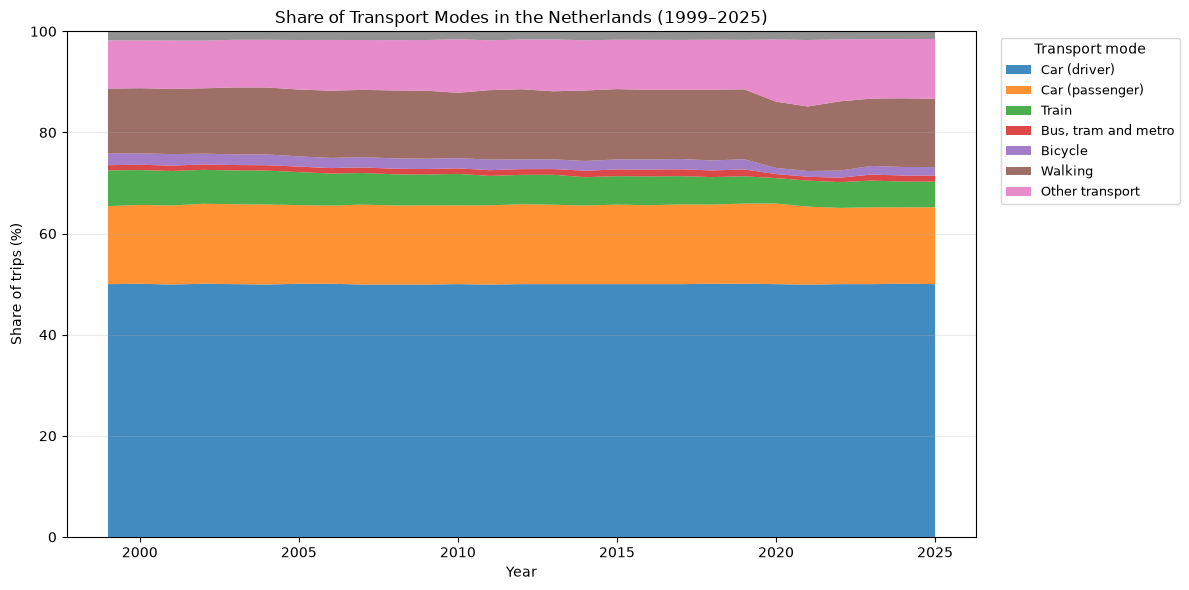

In [13]:
# Select transport modes for the total population
# and all travel purposes
columns = [
    col for col in df.columns
    if col[0] != "Perioden"
    and col[0] != "Totaal"
    and col[1] == "Totaal"
    and col[2] == "Totaal"
]

# Extract years
years = pd.to_numeric(
    df.iloc[:, 0].astype(str).str.replace("*", "", regex=False),
    errors="coerce"
)

# Keep years 1999–2025
mask = years.between(1999, 2025)

# Create a dataframe with transport modes
data = df.loc[mask, columns].copy()
data.index = years[mask].astype(int)

# Calculate the percentage share per year
shares = data.div(data.sum(axis=1), axis=0) * 100

# Give transport modes readable names
labels = [
    "Car (driver)",
    "Car (passenger)",
    "Train",
    "Bus, tram and metro",
    "Bicycle",
    "Walking",
    "Other transport"
]

# Check the number and order of transport modes
print("Selected columns:")
for i, col in enumerate(shares.columns):
    print(i, col)

# Plot a 100% stacked area chart
plt.figure(figsize=(12, 6))

plt.stackplot(
    shares.index,
    shares.T,
    labels=labels[:len(shares.columns)],
    alpha=0.85
)

plt.xlabel("Year")
plt.ylabel("Share of trips (%)")
plt.title("Share of Transport Modes in the Netherlands (1999–2025)")
plt.ylim(0, 100)
plt.legend(
    title="Transport mode",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()